<a href="https://colab.research.google.com/github/NurSyahira02/Hospital-Booking-App/blob/main/Scientific_Visualization_Data_Merging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Household Income

In [1]:
# If not already installed, do: pip install pandas fastparquet
import pandas as pd

URL_DATA = 'https://storage.dosm.gov.my/hies/hh_income_state.parquet'

df_income = pd.read_parquet(URL_DATA)
if 'date' in df_income.columns: df_income['date'] = pd.to_datetime(df_income['date'])

print(df_income)

              state       date  income_mean  income_median
0             Johor 1970-01-01          237            NaN
1             Johor 1974-01-01          382          269.0
2             Johor 1976-01-01          513          370.0
3             Johor 1979-01-01          731          518.0
4             Johor 1984-01-01         1065          793.0
..              ...        ...          ...            ...
314  W.P. Putrajaya 2016-01-01        11555         8275.0
315  W.P. Putrajaya 2019-01-01        12840         9983.0
316  W.P. Putrajaya 2020-01-01        12322         9743.0
317  W.P. Putrajaya 2022-01-01        13473        10056.0
318  W.P. Putrajaya 2024-01-01        13846        10769.0

[319 rows x 4 columns]


Household Amenities

In [2]:
# If not already installed, do: pip install pandas fastparquet
import pandas as pd

URL_DATA = 'https://storage.dosm.gov.my/hies/hh_access_amenities.parquet'

df_amenities = pd.read_parquet(URL_DATA)
if 'date' in df_amenities.columns: df_amenities['date'] = pd.to_datetime(df_amenities['date'])

print(df_amenities)

          date           state        district  piped_water  sanitation  \
0   2016-01-01           Johor   All Districts         99.9       99.99   
1   2019-01-01           Johor   All Districts         99.9       99.90   
2   2022-01-01           Johor   All Districts         99.6      100.00   
3   2024-01-01           Johor   All Districts         99.8      100.00   
4   2016-01-01           Johor      Batu Pahat         99.9      100.00   
..         ...             ...             ...          ...         ...   
689 2024-01-01     W.P. Labuan     W.P. Labuan        100.0      100.00   
690 2016-01-01  W.P. Putrajaya  W.P. Putrajaya        100.0      100.00   
691 2019-01-01  W.P. Putrajaya  W.P. Putrajaya        100.0      100.00   
692 2022-01-01  W.P. Putrajaya  W.P. Putrajaya        100.0      100.00   
693 2024-01-01  W.P. Putrajaya  W.P. Putrajaya        100.0      100.00   

     electricity  
0          100.0  
1          100.0  
2          100.0  
3          100.0  
4   

Marriages

In [3]:
# If not already installed, do: pip install pandas fastparquet
import pandas as pd

URL_DATA = 'https://storage.dosm.gov.my/demography/marriages_state.parquet'

df_marriage = pd.read_parquet(URL_DATA)
if 'date' in df_marriage.columns: df_marriage['date'] = pd.to_datetime(df_marriage['date'])

print(df_marriage)

              state       date     sex    abs   rate
0             Johor 2017-01-01  female  27308  27.59
1             Johor 2017-01-01    male  27626  25.82
2             Johor 2018-01-01  female  26806  26.70
3             Johor 2018-01-01    male  27153  25.20
4             Johor 2019-01-01  female  26574  26.40
..              ...        ...     ...    ...    ...
251  W.P. Putrajaya 2022-01-01    male    547  16.90
252  W.P. Putrajaya 2023-01-01  female    458  13.10
253  W.P. Putrajaya 2023-01-01    male    495  15.00
254  W.P. Putrajaya 2024-01-01  female    460  13.00
255  W.P. Putrajaya 2024-01-01    male    509    NaN

[256 rows x 5 columns]


Filter 3 datasets

In [5]:
# Filter df_income, df_amenities, and df_marriage for years 2019 until 2024
df_income_filtered = df_income[(df_income['date'].dt.year >= 2019) & (df_income['date'].dt.year <= 2024)]
df_amenities_filtered = df_amenities[(df_amenities['date'].dt.year >= 2019) & (df_amenities['date'].dt.year <= 2024)]
df_marriage_filtered = df_marriage[(df_marriage['date'].dt.year >= 2019) & (df_marriage['date'].dt.year <= 2024)]

print("Filtered Income (2019-2024):")
print(df_income_filtered.head())
print("\nFiltered Amenities (2019-2024):")
print(df_amenities_filtered.head())
print("\nFiltered Marriages (2019-2024):")
print(df_marriage_filtered.head())

Filtered Income (2019-2024):
    state       date  income_mean  income_median
18  Johor 2019-01-01         8013         6427.0
19  Johor 2020-01-01         7264         5690.0
20  Johor 2022-01-01         8517         6879.0
21  Johor 2024-01-01         9484         7712.0
40  Kedah 2019-01-01         5522         4325.0

Filtered Amenities (2019-2024):
        date  state       district  piped_water  sanitation  electricity
1 2019-01-01  Johor  All Districts         99.9        99.9        100.0
2 2022-01-01  Johor  All Districts         99.6       100.0        100.0
3 2024-01-01  Johor  All Districts         99.8       100.0        100.0
5 2019-01-01  Johor     Batu Pahat        100.0       100.0        100.0
6 2022-01-01  Johor     Batu Pahat        100.0       100.0        100.0

Filtered Marriages (2019-2024):
   state       date     sex    abs  rate
4  Johor 2019-01-01  female  26574  26.4
5  Johor 2019-01-01    male  26872  25.1
6  Johor 2020-01-01  female  22917  22.7
7  Johor 

Merge Datasets

In [6]:
# Merge df_marriage_filtered with df_income_filtered and df_amenities_filtered by 'state', 'date', and 'sex'
# Since income and amenities do not have 'sex', they will merge on 'state' and 'date'.

# First, merge marriages and income
df_merged = pd.merge(
    df_marriage_filtered,
    df_income_filtered,
    on=['state', 'date'],
    how='inner'
)

# Second, merge with amenities (keeping in mind amenities has 'district' level data, so we might want to clarify or aggregate.
# If we filter for 'All Districts' in amenities, it aligns at the state level)
df_amenities_state = df_amenities_filtered[df_amenities_filtered['district'] == 'All Districts']

df_final_merge = pd.merge(
    df_merged,
    df_amenities_state.drop(columns=['district']),
    on=['state', 'date'],
    how='inner'
)

print("Merged DataFrame shape:", df_final_merge.shape)
print(df_final_merge.head())

Merged DataFrame shape: (72, 10)
   state       date     sex    abs  rate  income_mean  income_median  \
0  Johor 2019-01-01  female  26574  26.4         8013         6427.0   
1  Johor 2019-01-01    male  26872  25.1         8013         6427.0   
2  Johor 2022-01-01  female  26539  25.8         8517         6879.0   
3  Johor 2022-01-01    male  26166  21.1         8517         6879.0   
4  Johor 2024-01-01  female  24757  24.2         9484         7712.0   

   piped_water  sanitation  electricity  
0         99.9        99.9        100.0  
1         99.9        99.9        100.0  
2         99.6       100.0        100.0  
3         99.6       100.0        100.0  
4         99.8       100.0        100.0  


Visualization - recommendation by Gemini

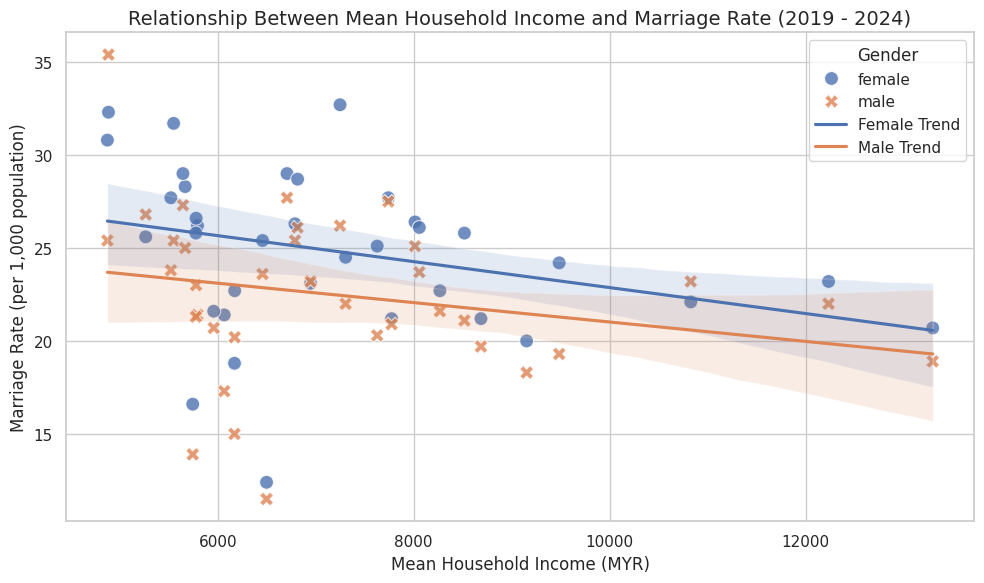

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Create scatter plot showing the relationship, styling by sex
sns.scatterplot(
    data=df_final_merge,
    x='income_mean',
    y='rate',
    hue='sex',
    style='sex',
    s=100,
    alpha=0.8
)

# Add trend lines for each sex to see the relationship pattern clearly
sns.regplot(
    data=df_final_merge[df_final_merge['sex'] == 'female'],
    x='income_mean',
    y='rate',
    scatter=False,
    label='Female Trend'
)
sns.regplot(
    data=df_final_merge[df_final_merge['sex'] == 'male'],
    x='income_mean',
    y='rate',
    scatter=False,
    label='Male Trend'
)

plt.title('Relationship Between Mean Household Income and Marriage Rate (2019 - 2024)', fontsize=14)
plt.xlabel('Mean Household Income (MYR)', fontsize=12)
plt.ylabel('Marriage Rate (per 1,000 population)', fontsize=12)
plt.legend(title='Gender')
plt.tight_layout()
plt.show()

/tmp/ipykernel_3544/248965955.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


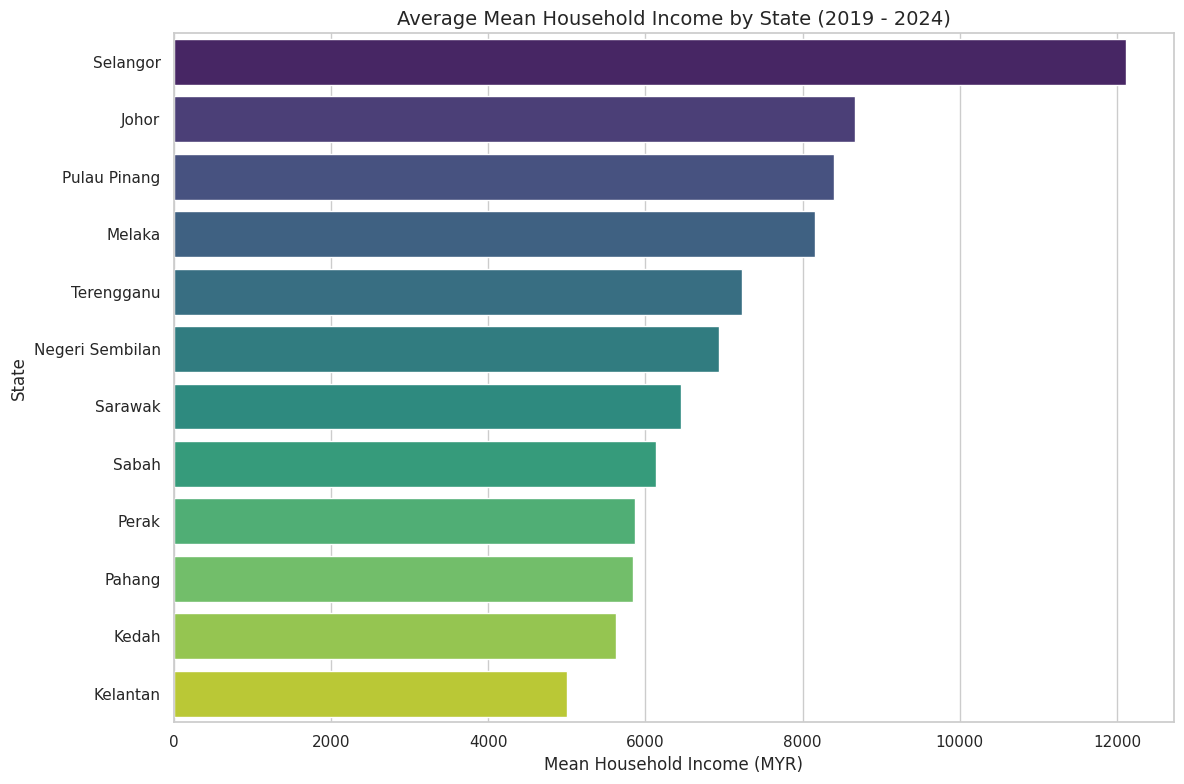

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the average mean income for each state to sort them
state_order = df_final_merge.groupby('state')['income_mean'].mean().sort_values(ascending=False).index

plt.figure(figsize=(12, 8))
sns.barplot(
    data=df_final_merge,
    x='income_mean',
    y='state',
    order=state_order,
    palette='viridis',
    errorbar=None
)

plt.title('Average Mean Household Income by State (2019 - 2024)', fontsize=14)
plt.xlabel('Mean Household Income (MYR)', fontsize=12)
plt.ylabel('State', fontsize=12)
plt.tight_layout()
plt.show()

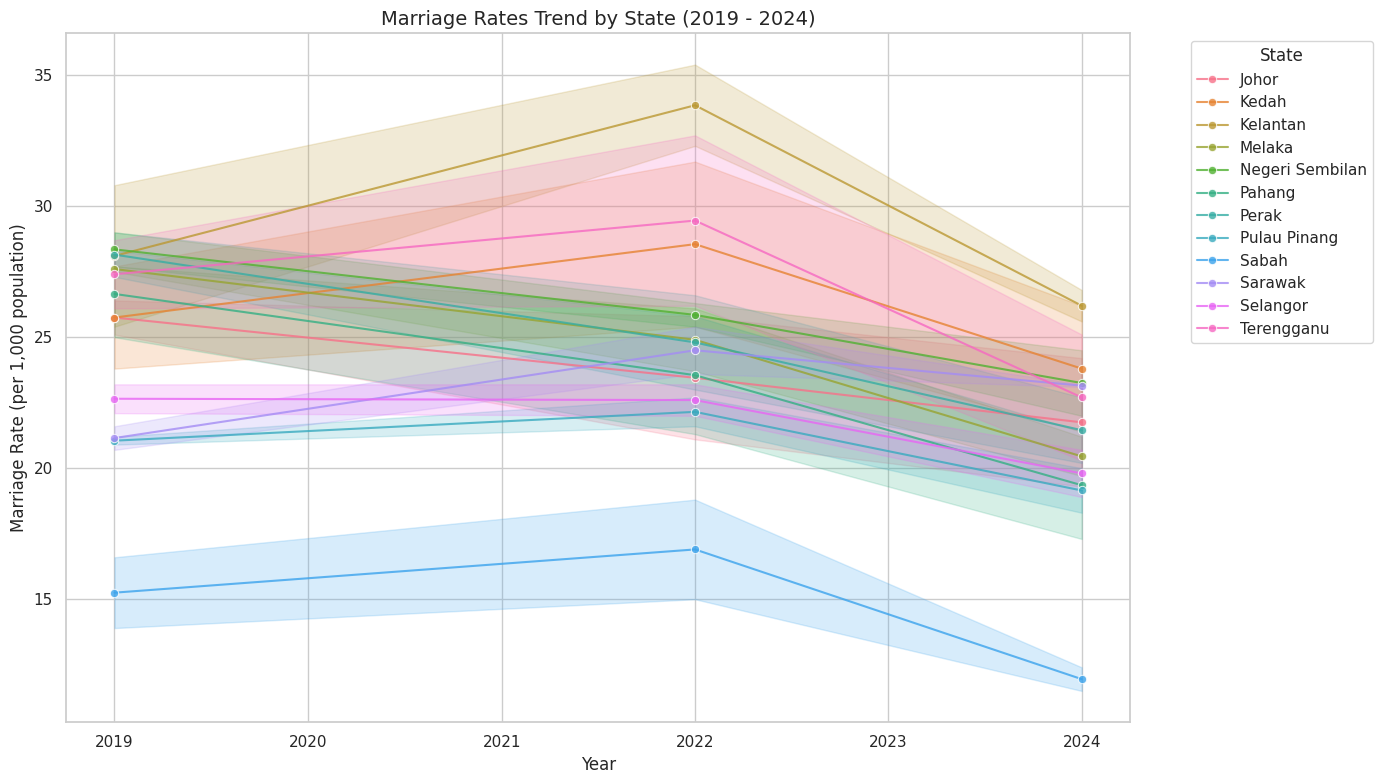

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Visualize overall marriage rate trend across all states (2019-2024)
plt.figure(figsize=(14, 8))
sns.lineplot(
    data=df_final_merge,
    x='date',
    y='rate',
    hue='state',
    marker='o',
    alpha=0.8
)
plt.title('Marriage Rates Trend by State (2019 - 2024)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Marriage Rate (per 1,000 population)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='State')
plt.tight_layout()
plt.show()

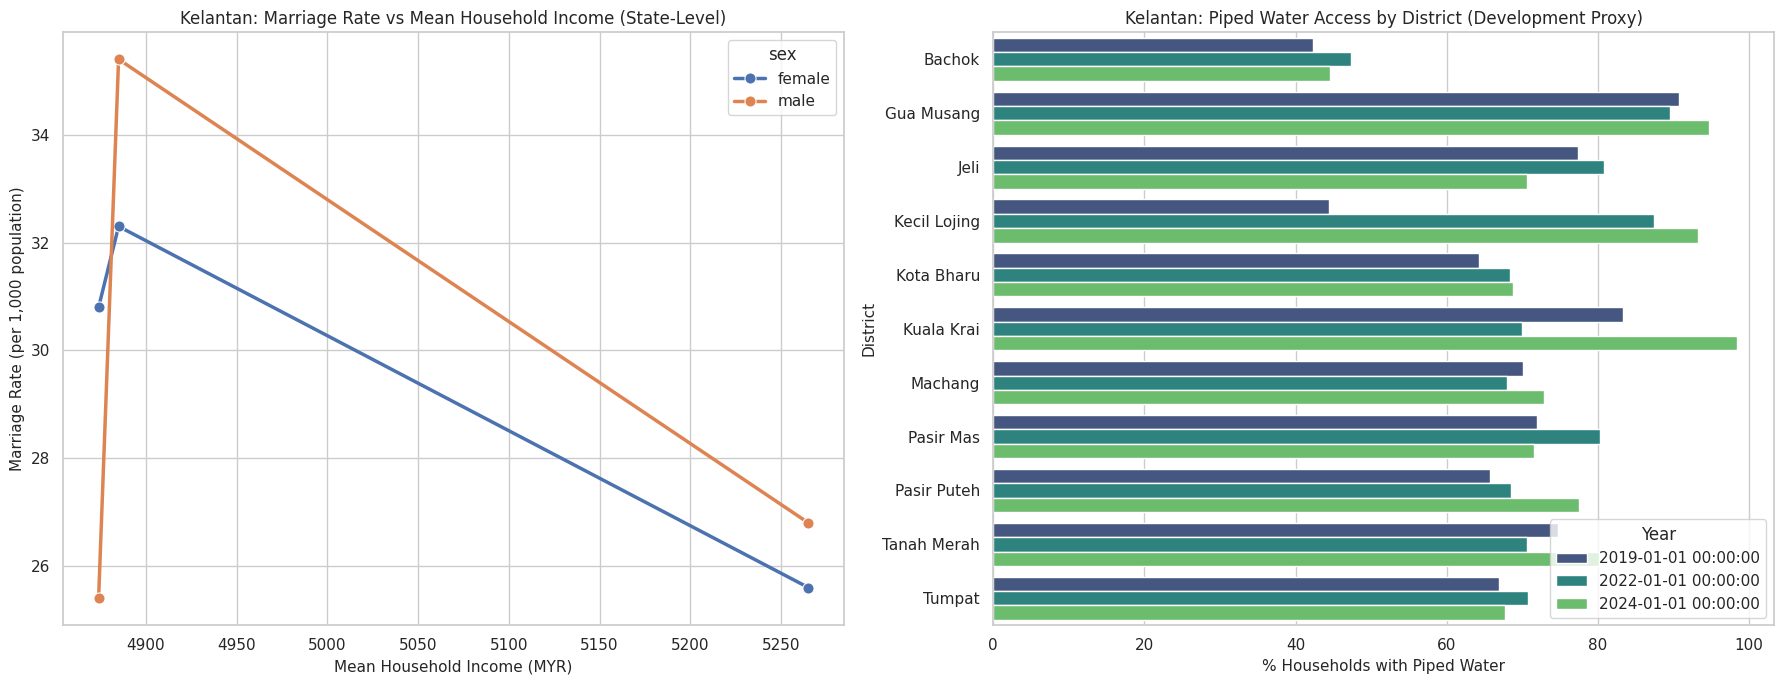

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter Kelantan's general state data
df_kel_state = df_final_merge[df_final_merge['state'] == 'Kelantan']

# Filter Kelantan's district amenities data
df_kel_districts = df_amenities_filtered[
    (df_amenities_filtered['state'] == 'Kelantan') &
    (df_amenities_filtered['district'] != 'All Districts')
]

# Create a 1x2 subplot figure
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: Marriage Rate vs State-level Mean Income in Kelantan (2019-2024)
sns.lineplot(
    ax=axes[0],
    data=df_kel_state,
    x='income_mean',
    y='rate',
    hue='sex',
    marker='o',
    linewidth=2.5,
    markersize=8
)
axes[0].set_title('Kelantan: Marriage Rate vs Mean Household Income (State-Level)', fontsize=12)
axes[0].set_xlabel('Mean Household Income (MYR)', fontsize=11)
axes[0].set_ylabel('Marriage Rate (per 1,000 population)', fontsize=11)

# Plot 2: Piped Water Access (Amenity Proxy) by District in Kelantan
sns.barplot(
    ax=axes[1],
    data=df_kel_districts,
    x='piped_water',
    y='district',
    hue='date',
    palette='viridis'
)
axes[1].set_title('Kelantan: Piped Water Access by District (Development Proxy)', fontsize=12)
axes[1].set_xlabel('% Households with Piped Water', fontsize=11)
axes[1].set_ylabel('District', fontsize=11)
axes[1].legend(title='Year')

plt.tight_layout()
plt.show()